# 9.B.2. Признаки из Prophet (bike sharing)

В 9.B.1 на коротком чистом ряде ни один признак из ETS не обогнал саму ETS. Здесь обратная
ситуация: почасовые прокаты велосипедов, у бустинга есть богатый календарь (час, день недели,
праздники), а Prophet сам по себе прогнозирует плохо. Вопрос тот же: **что Prophet добавляет
к календарю?**

Данные — Kaggle Bike Sharing Demand, 2011–2012, горизонт H = 168 часов (неделя).

In [1]:
import common  # первым: глушит предупреждения библиотек при импорте

common.quiet()

import logging  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from catboost import CatBoostRegressor  # noqa: E402
from prophet import Prophet  # noqa: E402

from common import mae  # noqa: E402

logging.getLogger("prophet").setLevel(logging.ERROR)
logging.getLogger("cmdstanpy").disabled = True  # логи Stan о каждом обучении Prophet
H = 168

## 0. Данные: дыры в календаре

Особенность, которую нужно разобрать первой: в данных **только 1–19 число каждого месяца**
(остальные дни Kaggle отложил в тест соревнования).

In [2]:
df = pd.read_csv(common.DATA / "bike_train.csv", parse_dates=["datetime"])
full = pd.date_range(df["datetime"].min(), df["datetime"].max(), freq="h")
print(f"{len(df)} часов из {len(full)} в календаре, пропущено {len(full) - len(df)}")
print("дни месяца в данных:", sorted(df["datetime"].dt.day.unique()))

train, test = df.iloc[:-H], df.iloc[-H:]
y = df["count"].to_numpy(float)
y_train, y_test = y[:-H], y[-H:]
print(f"test: {test['datetime'].min()} … {test['datetime'].max()}")

10886 часов из 17256 в календаре, пропущено 6370
дни месяца в данных: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
test: 2012-12-13 00:00:00 … 2012-12-19 23:00:00


Что из этого следует:

- **лаги по строкам опасны**: `shift(168)` — это 168 строк назад, а через дыру 20–31 числа это
  может оказаться 12 днями, а не неделей. Поэтому здесь мы вообще не используем лаги — только
  календарь и Prophet, которым дыры не мешают (у них признак — сама дата);
- **признак «день месяца» вреден**: он есть в исходном ноутбуке 9.5, но в train нет ни одного
  дня после 19-го, и модель выучит ложную закономерность о «конце месяца»;
- тест — последняя неделя, 13–19 декабря 2012, она непрерывна, и неделя перед ней (6–12 декабря)
  тоже, поэтому сезонный наивный прогноз «неделю назад» считается корректно. Берём его
  **по времени**, а не по строкам.

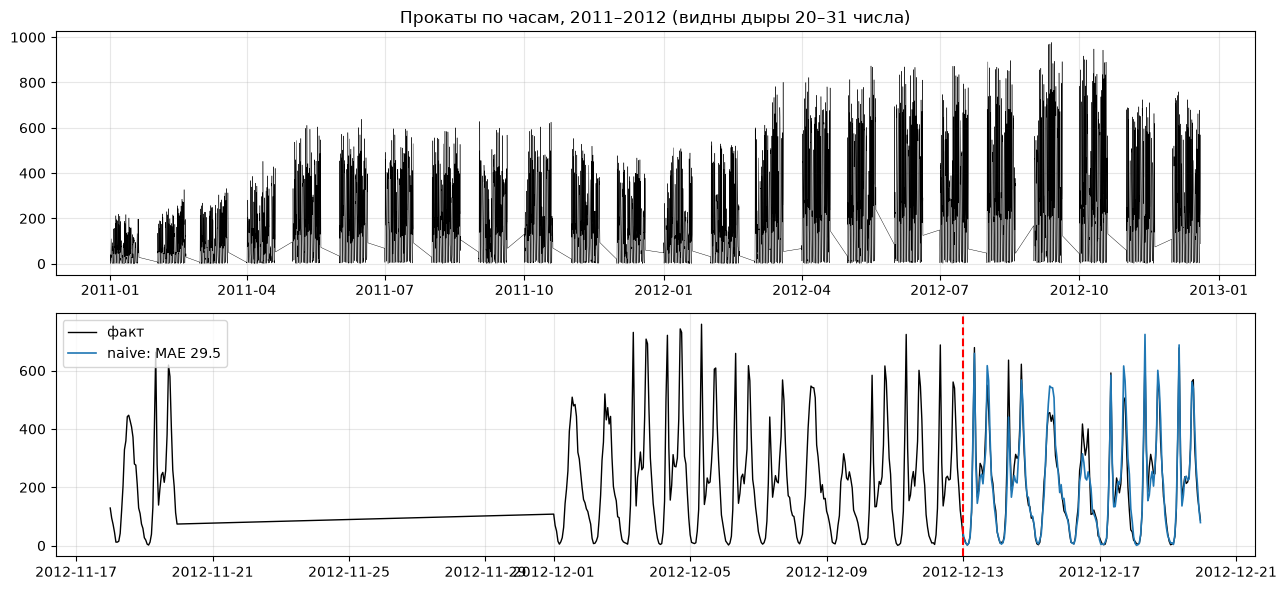

In [3]:
by_time = df.set_index("datetime")["count"]
naive = by_time.reindex(test["datetime"] - pd.Timedelta(hours=H)).to_numpy()
results = {"naive (неделю назад)": {"MAE": mae(y_test, naive), "±": 0.0}}

fig, axes = plt.subplots(2, 1, figsize=(13, 6))
axes[0].plot(df["datetime"], y, lw=0.3, color="black")
axes[0].set_title("Прокаты по часам, 2011–2012 (видны дыры 20–31 числа)")
last = df.iloc[-3 * H :]
axes[1].plot(last["datetime"], last["count"], color="black", lw=1, label="факт")
axes[1].plot(test["datetime"], naive, lw=1.2, label=f"naive: MAE {mae(y_test, naive):.1f}")
axes[1].axvline(test["datetime"].iloc[0], color="red", ls="--")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()

Два суточных профиля: в рабочие дни — пики утром и вечером (дорога на работу), в выходные — один
пик днём. Плюс годовая сезонность (зимой меньше) и рост сервиса от 2011 к 2012 году.

## 1. Prophet сам по себе

Prophet = тренд + сезонности (суточная, недельная, годовая) + праздники. Обучаем только на train;
компоненты на всех датах (train и test) берём одним вызовом `predict`.

In [4]:
prophet_df = df.rename(columns={"datetime": "ds", "count": "y"})[["ds", "y"]]
prophet = Prophet(yearly_seasonality=True).fit(prophet_df.iloc[:-H])
components = prophet.predict(prophet_df[["ds"]])
prophet_forecast = components["yhat"].to_numpy()[-H:]
results["Prophet"] = {"MAE": mae(y_test, prophet_forecast), "±": 0.0}
print(f"Prophet: MAE = {results['Prophet']['MAE']:.1f}, naive: {results['naive (неделю назад)']['MAE']:.1f}")

Prophet: MAE = 70.3, naive: 29.5


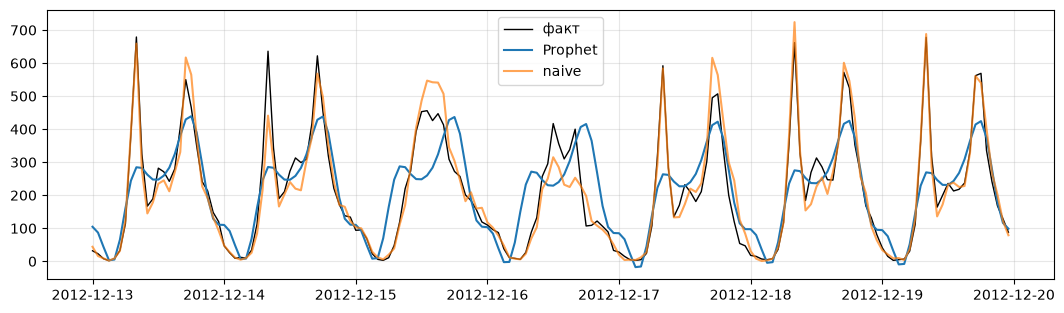

In [5]:
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(test["datetime"], y_test, color="black", lw=1, label="факт")
ax.plot(test["datetime"], prophet_forecast, label="Prophet")
ax.plot(test["datetime"], naive, label="naive", alpha=0.7)
ax.legend()
ax.grid(alpha=0.3);

Prophet намного хуже наивного. Его суточная сезонность — **один профиль на все дни**: он не знает,
что в выходные утреннего пика нет. Аддитивная модель к тому же не умеет «рабочий день × час».
Бустинг по календарю такие взаимодействия ловит сам — поэтому интересен не Prophet как прогноз,
а Prophet как источник признаков.

## 2. Какие компоненты Prophet нужны бустингу

Базовые признаки — календарь: час, день недели, месяц, праздник, рабочий день (`holiday` и
`workingday` известны заранее). К ним по очереди добавляем компоненты Prophet.

Каждый вариант обучаем с тремя сидами CatBoost и показываем среднее ± разброс: разница между
вариантами бывает меньше, чем шум от сида.

In [6]:
calendar = pd.DataFrame(
    {
        "hour": df["datetime"].dt.hour,
        "day_of_week": df["datetime"].dt.dayofweek,
        "month": df["datetime"].dt.month,
        "holiday": df["holiday"],
        "workingday": df["workingday"],
    }
)
prophet_features = components[["trend", "daily", "weekly", "yearly", "yhat"]].set_axis(df.index)


def evaluate(name, X, target=y, post=lambda p: p, seeds=(0, 1, 2)):
    """CatBoost на X[:-H] → прогноз X[-H:]; post — обратное преобразование прогноза. MAE по сидам."""
    scores = []
    for seed in seeds:
        model = CatBoostRegressor(iterations=500, depth=4, random_seed=seed, verbose=False)
        model.fit(X.iloc[:-H], target[:-H])
        scores.append(mae(y_test, post(model.predict(X.iloc[-H:]))))
    results[name] = {"MAE": np.mean(scores), "±": np.std(scores)}
    print(f"{name:35s} MAE {np.mean(scores):5.1f} ± {np.std(scores):.1f}")
    return model


def with_prophet(*cols):
    return pd.concat([calendar, prophet_features[list(cols)]], axis=1)


evaluate("календарь", calendar)
for col in ("trend", "daily", "weekly", "yearly"):
    evaluate(f"календарь + {col}", with_prophet(col))
evaluate("календарь + trend, daily, weekly", with_prophet("trend", "daily", "weekly"))
evaluate("календарь + все компоненты", with_prophet("trend", "daily", "weekly", "yearly"))
evaluate("календарь + yhat", with_prophet("yhat"));

календарь                           MAE  46.8 ± 0.1


календарь + trend                   MAE  39.4 ± 4.5


календарь + daily                   MAE  46.4 ± 0.1


календарь + weekly                  MAE  46.5 ± 0.1


календарь + yearly                  MAE  69.5 ± 0.8


календарь + trend, daily, weekly    MAE  24.4 ± 0.2


календарь + все компоненты          MAE  23.7 ± 0.1


календарь + yhat                    MAE  28.1 ± 0.6


Что видно:

- **сезонности Prophet поодиночке бесполезны**: `daily` и `weekly` — гладкие функции часа и дня
  недели, которые у бустинга уже есть; `yearly` на двух годах истории неустойчива и поодиночке
  вредит (в сочетании с трендом — уже нет);
- **тренд — единственный «новый» признак**: календарь ничего не знает о том, что сервис вырос
  за 2011–2012. Но один тренд даёт нестабильный результат (большой разброс по сидам), а в
  паре с сезонностями — лучший;
- `yhat` — тоже хорошо, но хуже, чем компоненты по отдельности: сумма компонент теряет информацию,
  которую дерево может использовать, разделяя их.

Проверим, что именно даёт тренд. Если дело в уровне ряда, то его можно получить и без Prophet.

In [7]:
t = np.arange(len(df))
print(f"корреляция тренда Prophet со временем: {np.corrcoef(prophet_features['trend'], t)[0, 1]:.3f}")
evaluate("календарь + год", calendar.assign(year=df["datetime"].dt.year));

корреляция тренда Prophet со временем: 0.996


календарь + год                     MAE  27.9 ± 0.5


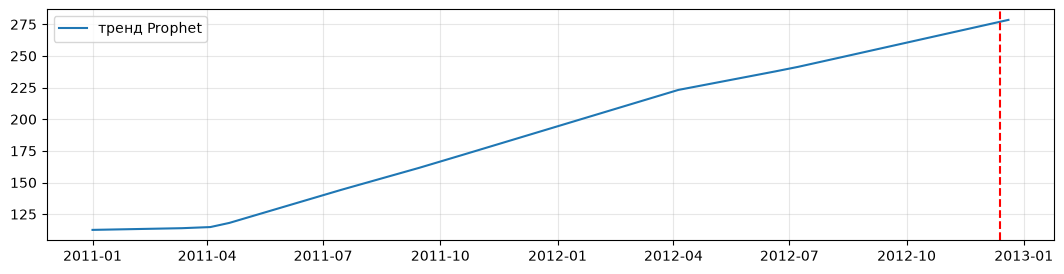

In [8]:
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(df["datetime"], prophet_features["trend"], label="тренд Prophet")
ax.axvline(test["datetime"].iloc[0], color="red", ls="--")
ax.legend()
ax.grid(alpha=0.3);

Тренд Prophet почти линеен по времени, а признак `year` даёт почти тот же выигрыш. То есть Prophet
здесь — дорогой способ сообщить бустингу **уровень ряда**: та же задача, что в блоке 1 решал
детрендинг.

Почему признак-тренд работает, хотя в 9.B.1 прогноз-признак проваливался из-за экстраполяции?
Тест — декабрь 2012, тренд на нём лишь чуть выше максимума train. Если прогнозировать дальше,
тренд уйдёт за пределы train, и дерево перестанет его «видеть» (9.A.1).

## 3. Остатки Prophet

Как в 9.B.1: target бустинга — отношение `y / trend`, а прогноз — `trend × модель(календарь)`.
Тренд экстраполирует Prophet, дерево учит только относительный профиль.

In [9]:
trend = prophet_features["trend"].to_numpy()
evaluate("y / trend ~ календарь", calendar, target=y / trend, post=lambda p: p * trend[-H:])
yhat = prophet_features["yhat"].to_numpy()
evaluate("y − yhat ~ календарь", calendar, target=y - yhat, post=lambda p: p + yhat[-H:]);

y / trend ~ календарь               MAE  28.8 ± 0.5


y − yhat ~ календарь                MAE  38.3 ± 0.1


- `y / trend` — устойчивый вариант без экстраполяции по признаку: качество близко к лучшему, разброс
  по сидам маленький. На длинном горизонте это предпочтительная схема.
- `y − yhat` — хуже: аддитивный остаток Prophet несёт его ошибки в суточном профиле (один профиль на
  рабочие и выходные дни), и бустингу приходится их исправлять, а не учить профиль с нуля.

## 4. Погода — признак-«оракул»

В исходном ноутбуке 9.5 в признаки попадают `temp`, `humidity`, `weather`, `windspeed`. В момент
прогноза **фактической погоды на неделю вперёд нет**. Посмотрим, сколько она «стоит».

In [10]:
weather = df[["weather", "temp", "atemp", "humidity", "windspeed"]]
evaluate("календарь + погода (оракул)", pd.concat([calendar, weather], axis=1))
evaluate("календарь + trend + погода (оракул)", pd.concat([with_prophet("trend"), weather], axis=1));

календарь + погода (оракул)         MAE  43.0 ± 0.7


календарь + trend + погода (оракул) MAE  29.1 ± 0.9


Даже фактическая погода не помогает так, как уровень ряда, — а на практике её нет вовсе. В реальности
вместо неё берут **прогноз погоды** (он есть на несколько дней вперёд, с ошибкой) и обучают модель
тоже на прогнозах погоды, а не на фактах — иначе это та же ловушка «на train признак точнее, чем на
тесте», что в 9.B.1.

## 5. Итоги

In [11]:
pd.DataFrame(results).T.round(1)

,MAE,±
naive (неделю назад),29.5,0.0
Prophet,70.3,0.0
календарь,46.8,0.1
календарь + trend,39.4,4.5
календарь + daily,46.4,0.1
календарь + weekly,46.5,0.1
календарь + yearly,69.5,0.8
"календарь + trend, daily, weekly",24.4,0.2
календарь + все компоненты,23.7,0.1
календарь + yhat,28.1,0.6


1. **Prophet как прогноз плох, как источник признаков полезен** — но только тем, чего нет в календаре.
   Здесь это **тренд** (уровень ряда); сезонности Prophet дублируют календарь. Наивный прогноз
   обгоняют только варианты «календарь + тренд + сезонности Prophet».
2. Тот же уровень даёт простой признак `year` — сначала проверяйте, нельзя ли получить «новое знание»
   дешевле, чем отдельной моделью на каждый ряд.
3. Признак-тренд работает, пока горизонт короткий и тренд не выходит за пределы train. Схема
   «остатки» (`y / trend`) безопаснее: экстраполирует Prophet, а не дерево.
4. Разброс по сидам сравним с разницей вариантов — без него легко «найти» несуществующий эффект.
5. Признаки, которых не будет в момент прогноза (фактическая погода), в обучение не берём.